# Laboratory Exercise 1: Volunteer Events

Volunteer Green is a platform that runs clean-up, planting, and restoration events for volunteers across Macedonia. Its pages are a stored snapshot in `data/site`, and the setup serves them from this machine, so every request stays on the local loopback address. The events are synthetic and describe no real person, group, or organization.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [2]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from playwright.async_api import async_playwright
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
# Every random step draws from this generator, so a rerun gives the same result.
rng = np.random.default_rng(2026)

In [100]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [101]:
# Every path is a file under the site directory.
class Service(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Service, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:63845/'

## Task 1: Collect the Events

The platform lists its events across several pages, and the first one is `catalogue/page-1.html` under `BASE`. Collect every event into a table named `events`, with one row per event and these columns:

- `event_id`, the identifier of the event,
- `activity`, `kind`, and `city`,
- `area` and `unit`, the area of the site and the unit it is quoted in, exactly as the event states them,
- `volunteers`, the number of volunteers who took part,
- `difficulty`, `day`, `audience`, and `leaders`, the number of team leaders, and
- `by_partner`, which is true when a partner group organised the event and false when the platform organised it.

An event that does not state a field has a missing value in that column. Report how many events the platform lists and over how many pages they are spread.

In [102]:
# Write your solution here.
current_url = urljoin(BASE, "catalogue/page-1.html")
rows = []
total_events_reported = 0
page_count = 0

pd.set_option('display.max_columns', None)

while current_url:
    page_count += 1
    response = requests.get(current_url, timeout=10)
    if response.status_code != 200:
        print(f"Failed to fetch page. Status code: {response.status_code}")
        break

    soup = BeautifulSoup(response.text, "html.parser")

    if page_count == 1:
        toolbar = soup.select_one(".toolbar")
        if toolbar:
            match = re.search(r"(\d+)", toolbar.get_text(strip=True))
            if match:
                total_events_reported = int(match.group(1))

    events_elements = soup.select(".results .event")

    for event in events_elements:
        # event_id
        event_id = event.get("data-id")

        # activity
        title_el = event.select_one(".title a")
        activity = title_el.get_text(strip=True) if title_el else np.nan

        # volunteers (numeric or NaN)
        vol_el = event.select_one(".turnout.figure")
        if vol_el:
            vol_match = re.search(r"(\d+)", vol_el.get_text(strip=True))
            volunteers = int(vol_match.group(1)) if vol_match else np.nan
        else:
            volunteers = np.nan

        # kind & city
        place = event.select_one(".place")
        kind = place.select_one(".kind").get_text(strip=True) if place and place.select_one(".kind") else np.nan
        city = place.city = place.select_one(".city").get_text(strip=True) if place and place.select_one(".city") else np.nan

        # area & unit
        summary = event.select_one(".summary")
        area, unit = np.nan, np.nan
        if summary:
            sum_text = summary.get_text(strip=True)
            m = re.search(r"([\d\s.]+)\s*(m²|ha)", sum_text)
            if m:
                area_str = m.group(1).replace(" ", "")
                area = float(area_str)
                unit = m.group(2)

        # tags: difficulty, day, audience, leaders
        tags = event.select_one(".tags")
        difficulty, day, audience, leaders = np.nan, np.nan, np.nan, np.nan
        if tags:
            diff_el = tags.select_one(".difficulty")
            difficulty = diff_el.get_text(strip=True) if diff_el else np.nan

            day_el = tags.select_one(".day")
            day = day_el.get_text(strip=True) if day_el else np.nan

            aud_el = tags.select_one(".audience")
            audience = aud_el.get_text(strip=True) if aud_el else np.nan

            lead_el = tags.select_one(".leaders")
            if lead_el:
                lm = re.search(r"(\d+)", lead_el.get_text(strip=True))
                leaders = int(lm.group(1)) if lm else np.nan

        # by_partner (True if partner group, False if Volunteer Green)
        org_el = event.select_one(".organiser.muted")
        by_partner = np.nan
        if org_el:
            org_text = org_el.get_text(strip=True)
            by_partner = "a partner group" in org_text.lower()

        rows.append({
            "event_id": event_id,
            "activity": activity,
            "kind": kind,
            "city": city,
            "area": area,
            "unit": unit,
            "volunteers": volunteers,
            "difficulty": difficulty,
            "day": day,
            "audience": audience,
            "leaders": leaders,
            "by_partner": by_partner
        })

    # Pagination next link
    next_link = soup.select_one("nav.pagination a.next")
    if next_link and next_link.get("href"):
        current_url = urljoin(current_url, next_link["href"])
    else:
        current_url = None

events = pd.DataFrame(rows)

print(f"Platform reports {total_events_reported} total events.")
print(f"Collected {len(events)} events spread across {page_count} pages.\n")
print(events.to_string(index=False))

Platform reports 192 total events.
Collected 192 events spread across 16 pages.

event_id              activity        kind     city     area unit  volunteers difficulty     day        audience  leaders  by_partner
  762809           Flower beds    Planting   Skopje 12900.00   m²        60.0   Moderate Weekday     Adults only      4.0        True
  113111 Playground repainting Restoration   Skopje     1.32   ha        45.0   Moderate Weekday Family-friendly      5.0       False
  593942 Playground repainting Restoration   Tetovo  8000.00   m²        38.0       Easy Weekend     Adults only      5.0       False
  653599           Flower beds    Planting   Skopje     2.97   ha       105.0  Demanding Weekend     Adults only      3.0       False
  937467    Lakeshore clean-up    Clean-up   Tetovo     1.27   ha         NaN   Moderate Weekend Family-friendly      1.0        True
  548375        Hedge planting    Planting   Skopje     0.55   ha         NaN       Easy Weekday     Adults only   

## Task 2: Add the Surveys

The home page of the platform, `index.html` under `BASE`, points to a page of site surveys. Collect every survey the page holds, and add the pieces of litter, of plastic, and of cigarette butts counted for each event to `events`, so that every event appears exactly once. Name the result `df`.

Report how many surveys the page says it holds, how many you collected, and what you did about any survey that would put an event in `df` more than once.

In [106]:
# Write your solution here.
survey_url = urljoin(BASE, "surveys.html")

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page()
    await page.goto(survey_url)
    await page.wait_for_selector("#surveys tbody tr .event-id", timeout=10000)
    html_content = await page.content()
    await browser.close()

soup = BeautifulSoup(html_content, "html.parser")
table_rows = soup.select("#surveys tbody tr")
survey_rows = []

for row in table_rows:
    if row.find("th"):
        continue
    event_id = row.select_one(".event-id").get_text(strip=True)
    litter = int(row.select_one(".litter").get_text(strip=True))
    plastic = int(row.select_one(".plastic").get_text(strip=True))
    butts = int(row.select_one(".butts").get_text(strip=True))
    survey_rows.append({"event_id": event_id, "litter": litter, "plastic": plastic, "butts": butts})

surveys_df = pd.DataFrame(survey_rows)

print(f"Surveys raw count: {len(surveys_df)}")
# Deduplicate surveys to ensure 1-to-1 matching with events
surveys_cleaned = surveys_df.drop_duplicates(subset=["event_id"], keep="first")

# Merge surveys into events dataframe
df = events.merge(surveys_cleaned, on="event_id", how="left")

print(f"Final df shape: {df.shape}")
print(df.to_string(index=False))

Surveys raw count: 193
Final df shape: (192, 15)
event_id              activity        kind     city     area unit  volunteers difficulty     day        audience  leaders  by_partner  litter  plastic  butts
  762809           Flower beds    Planting   Skopje 12900.00   m²        60.0   Moderate Weekday     Adults only      4.0        True      33       14      4
  113111 Playground repainting Restoration   Skopje     1.32   ha        45.0   Moderate Weekday Family-friendly      5.0       False      40       22     14
  593942 Playground repainting Restoration   Tetovo  8000.00   m²        38.0       Easy Weekend     Adults only      5.0       False      69       41      5
  653599           Flower beds    Planting   Skopje     2.97   ha       105.0  Demanding Weekend     Adults only      3.0       False      57       15     29
  937467    Lakeshore clean-up    Clean-up   Tetovo     1.27   ha         NaN   Moderate Weekend Family-friendly      1.0        True     291      140     85
  5

## Task 3: Describe the Events

Answer each request below from `df`. Support each answer with the numbers that establish it, and with a figure wherever the request asks you to show something.

### 3.1 Column Types

Give every column of `df` a type that matches what it measures. The difficulty levels have a natural order, from easy to demanding, and the type of `difficulty` keeps it.

In [107]:
# Write your solution here.
diff_order = ["Easy", "Moderate", "Demanding"]
diff_type = pd.CategoricalDtype(categories=diff_order, ordered=True)

df = df.astype({
    "event_id": "string",
    "activity": "string",
    "kind": "category",
    "city": "category",
    "area": "float64",
    "unit": "category",
    "volunteers": "float64",
    "difficulty": diff_type,
    "day": "category",
    "audience": "category",
    "leaders": "float64",
    "by_partner": "boolean",
    "litter": "Int64",
    "plastic": "Int64",
    "butts": "Int64"
})

print(df.dtypes)

event_id        string
activity        string
kind          category
city          category
area           float64
unit          category
volunteers     float64
difficulty    category
day           category
audience      category
leaders        float64
by_partner     boolean
litter           Int64
plastic          Int64
butts            Int64
dtype: object


### 3.2 What Is Missing

Count the missing values in each column, show where they fall, and find out whether the absence of a value depends on another column.

Missing counts per column:
event_id       0
activity       0
kind           0
city           0
area           0
unit           0
volunteers    47
difficulty     0
day            0
audience       0
leaders       22
by_partner     0
litter         0
plastic        0
butts          0
dtype: int64


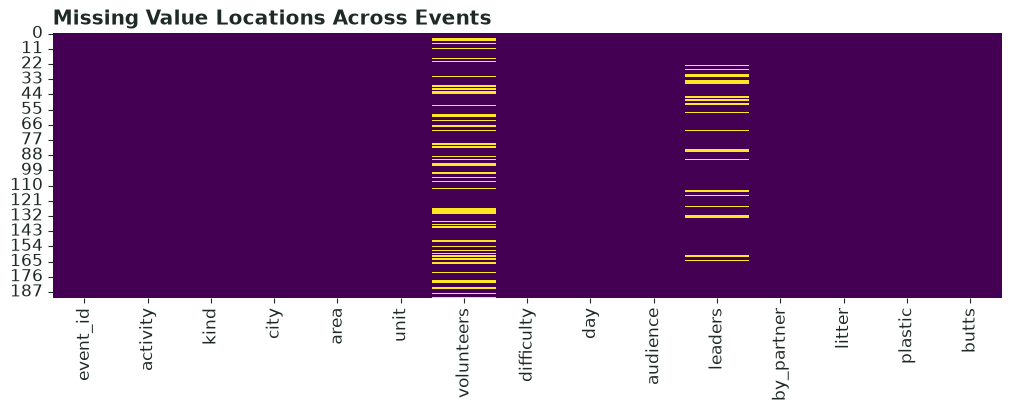


Turnout Missingness by Organizer Type:
            Present (%)  Missing (%)
by_partner                          
False             90.28         9.72
True              31.25        68.75


In [110]:
# Write your solution here.
missing_summary = df.isna().sum()
print("Missing counts per column:")
print(missing_summary)

plt.figure(figsize=(10, 4))
sns.heatmap(df.isna(), cbar=False, cmap="viridis")
plt.title("Missing Value Locations Across Events")
plt.show()

# Dependency check: missing volunteers vs by_partner
crosstab_partner = pd.crosstab(df["by_partner"], df["volunteers"].isna(), normalize="index") * 100
crosstab_partner.columns = ["Present (%)", "Missing (%)"]
print("\nTurnout Missingness by Organizer Type:")
print(crosstab_partner.round(2))

### 3.3 Areas in Two Units

Some events quote the area of the site in hectares and others in square metres. Compare the quoted areas within each unit, then add a column `area_ha` that states every area in hectares.

In [112]:
# Write your solution here.
print(df.groupby("unit")["area"].describe())

df["area_ha"] = np.where(df["unit"] == "m²", df["area"] / 10000.0, df["area"])
print(df[["area", "unit", "area_ha"]].head())

      count          mean          std      min       25%       50%       75%       max
unit                                                                                   
ha    165.0      1.302121     0.701505     0.42      0.75      1.16      1.61      4.07
m²     27.0  13925.925926  5408.866837  5800.00  11050.00  13200.00  15050.00  26700.00
       area unit  area_ha
0  12900.00   m²     1.29
1      1.32   ha     1.32
2   8000.00   m²     0.80
3      2.97   ha     2.97
4      1.27   ha     1.27


### 3.4 The Turnout

Describe the number of volunteers by its centre, its spread, and the shape of its distribution, and show the distribution. Decide which summary of the centre describes a typical event better.

Mean: 62.52, Std: 25.31
Median: 59.00, IQR: 30.00


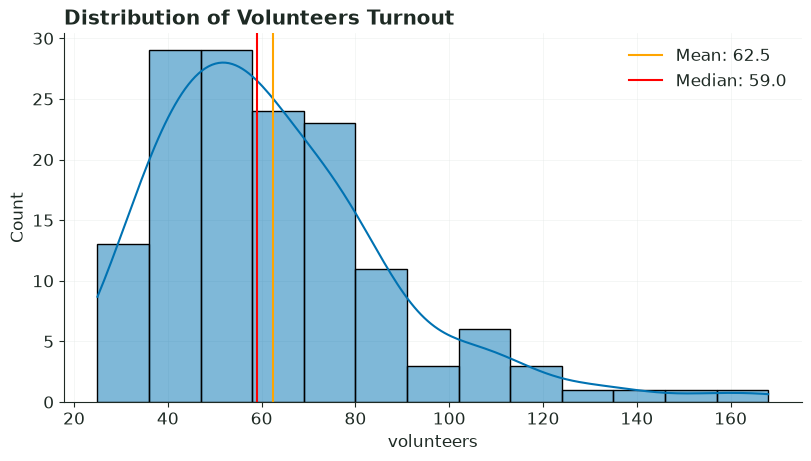

In [116]:
# Write your solution here.
vol = df["volunteers"].dropna()
mean_volunteers = vol.mean()
median_volunteers = vol.median()
std_volunteers = vol.std()
iqr_volunteers = stats.iqr(vol)

print(f"Mean: {mean_volunteers:.2f}, Std: {std_volunteers:.2f}")
print(f"Median: {median_volunteers:.2f}, IQR: {iqr_volunteers:.2f}")

plt.figure()
sns.histplot(vol, kde=True)
plt.axvline(mean_volunteers, color="orange", label=f"Mean: {mean_volunteers:.1f}")
plt.axvline(median_volunteers, color="red", label=f"Median: {median_volunteers:.1f}")
plt.title("Distribution of Volunteers Turnout")
plt.legend()
plt.show()

### 3.5 Turnout by Difficulty

Compare the number of volunteers across the difficulty levels.

            count       mean        std   min   25%   50%    75%    max
difficulty                                                             
Easy         45.0  47.155556  18.732514  25.0  36.0  44.0   53.0  136.0
Moderate     65.0  60.876923  19.868716  32.0  48.0  59.0   69.0  155.0
Demanding    35.0  85.314286  25.749668  41.0  74.5  81.0  103.0  168.0


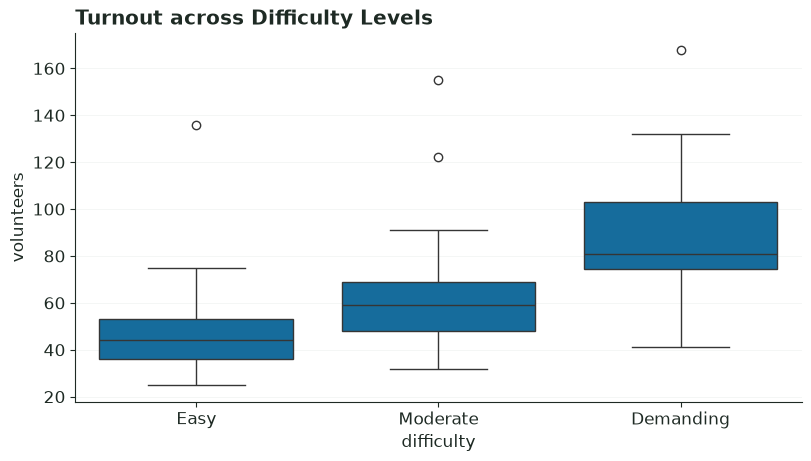

In [123]:
# Write your solution here.
print(df.groupby("difficulty", observed = False)["volunteers"].describe())
plt.figure()
sns.boxplot(data=df, x="difficulty", y="volunteers")
plt.title("Turnout across Difficulty Levels")
plt.show()

### 3.6 Events by City

Show how the events are spread across the cities, and give the share of events in each city.

          Count  Share (%)
city                      
Skopje       95      49.48
Tetovo       24      12.50
Bitola       23      11.98
Ohrid        22      11.46
Prilep       15       7.81
Kumanovo     13       6.77


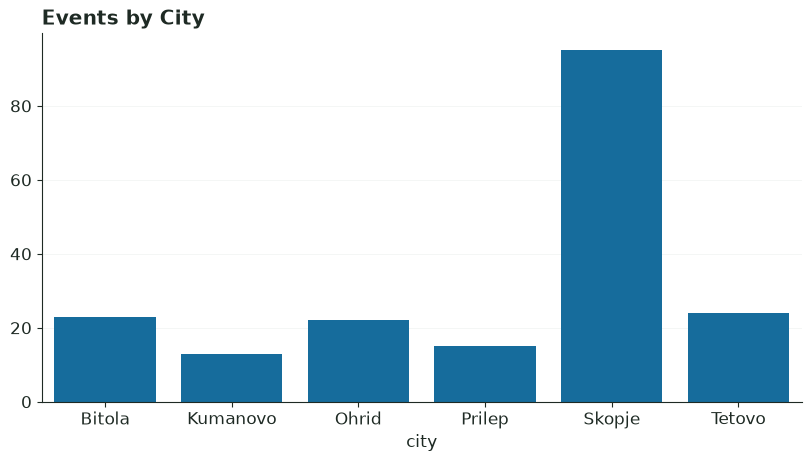

In [126]:
# Write your solution here.
city_counts = df["city"].value_counts()
city_shares = df["city"].value_counts(normalize=True) * 100

summary_city = pd.DataFrame({"Count": city_counts, "Share (%)": city_shares.round(2)})
print(summary_city)

plt.figure()
sns.barplot(x=city_counts.index, y=city_counts.values)
plt.title("Events by City")
plt.show()

### 3.7 Litter and Plastic

Show how the pieces of litter and the pieces of plastic counted on a plot move together, and measure how strongly they do. Decide whether the relationship is close to a straight line.

Pearson Correlation: 0.971 (p-value: 1.191e-120)


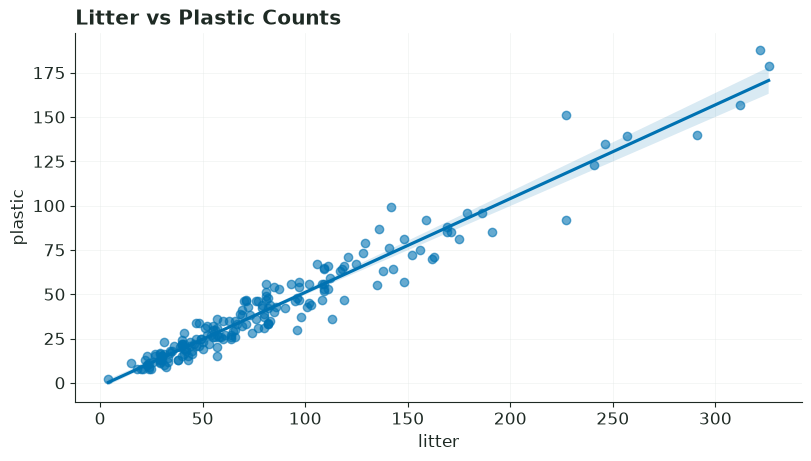

In [128]:
# Write your solution here.
valid_lp = df.dropna(subset=["litter", "plastic"])
r, p_val = stats.pearsonr(valid_lp["litter"], valid_lp["plastic"])

print(f"Pearson Correlation: {r:.3f} (p-value: {p_val:.3e})")

plt.figure()
sns.regplot(data=df, x="litter", y="plastic", scatter_kws={'alpha':0.6})
plt.title("Litter vs Plastic Counts")
plt.show()

### 3.8 Every Pair of Numeric Columns

Show how strongly every pair of numeric columns moves together, measured by the Spearman correlation, and name the pair that moves together most strongly.

Spearman Correlation Matrix:
             area  volunteers  leaders  litter  plastic  butts  area_ha
area        1.000       0.472    0.022   0.020   -0.003  0.085    0.833
volunteers  0.472       1.000    0.309  -0.038   -0.034  0.071    0.680
leaders     0.022       0.309    1.000  -0.004   -0.016 -0.051    0.044
litter      0.020      -0.038   -0.004   1.000    0.961  0.739    0.014
plastic    -0.003      -0.034   -0.016   0.961    1.000  0.720   -0.012
butts       0.085       0.071   -0.051   0.739    0.720  1.000    0.146
area_ha     0.833       0.680    0.044   0.014   -0.012  0.146    1.000


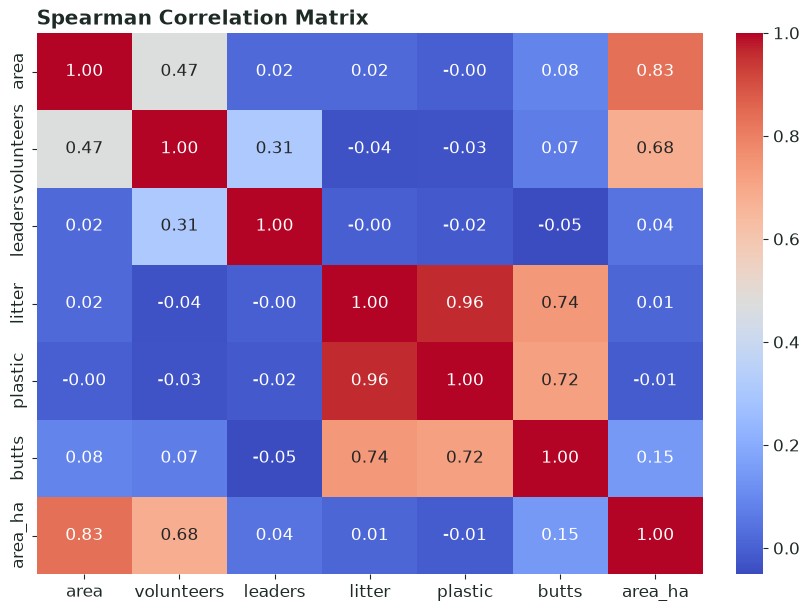

In [129]:
# Write your solution here.
num_cols = df.select_dtypes(include=[np.number]).columns
spearman_corr = df[num_cols].corr(method="spearman")

print("Spearman Correlation Matrix:")
print(spearman_corr.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(spearman_corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Spearman Correlation Matrix")
plt.show()

### 3.9 Turnout by City and Difficulty

Find the combination of city and difficulty with the highest median number of volunteers, counting only the combinations with at least three events that state a turnout.

In [131]:
# Write your solution here.
filtered = df.groupby(["city", "difficulty"], observed=False)["volunteers"].filter(lambda x: x.notna().sum() >= 3)
group_medians = df.loc[filtered.index].groupby(["city", "difficulty"], observed=False)["volunteers"].median()

print("Median Turnout for City/Difficulty combinations (n >= 3):")
print(group_medians.sort_values(ascending=False))

Median Turnout for City/Difficulty combinations (n >= 3):
city      difficulty
Ohrid     Demanding     103.0
Tetovo    Demanding      90.5
Prilep    Demanding      79.0
Kumanovo  Demanding      77.5
Skopje    Demanding      77.0
Prilep    Moderate       74.0
Bitola    Moderate       65.0
          Easy           61.0
Skopje    Moderate       59.0
Kumanovo  Moderate       55.0
Tetovo    Moderate       54.5
Ohrid     Moderate       53.0
Tetovo    Easy           46.0
Ohrid     Easy           44.0
Skopje    Easy           39.0
Bitola    Demanding       NaN
Kumanovo  Easy            NaN
Prilep    Easy            NaN
Name: volunteers, dtype: float64


## Task 4: Turnout

Use a significance level of 5 % and a confidence level of 95 % for every decision and every range in this task and the next. For each question, state the decision and give the range beside it. The questions of this task concern the events that state a turnout.

### 4.1 The Advertised Turnout

The home page states an average number of volunteers per event. Decide whether the average turnout of the events differs from that statement, and give a range for the average turnout.

In [139]:
# Write your solution here.
home_url = urljoin(BASE, "index.html")
home_response = requests.get(home_url, timeout=10)

if home_response.status_code != 200:
    print(f"Failed to fetch page. Status code: {response.status_code}")
    exit(1)

home_soup = BeautifulSoup(home_response.text, "html.parser")

advertised_mean = 1.0
for panel in home_soup.select(".panel"):
    text = panel.get_text()
    if "volunteers on average" in text:
        match = re.search(r"(\d+(?:\.\d+)?)", text)
        if match:
            advertised_mean = float(match.group(1))
            break

vol_data = df["volunteers"].dropna()
t_stat, p_val = stats.ttest_1samp(vol_data, advertised_mean)
ci = stats.t.interval(0.95, df=len(vol_data)-1, loc=vol_data.mean(), scale=stats.sem(vol_data))

print(f"Mean: {vol_data.mean():.2f}")
print(f"Range: [{ci[0]:.2f}, {ci[1]:.2f}]")
print(f"t-statistic: {t_stat:.3f}, p-value: {p_val:.4f}")

Mean: 62.52
Range: [58.36, 66.67]
t-statistic: 2.149, p-value: 0.0333


### 4.2 Weekend and Weekday

Decide whether the events held at the weekend and on a weekday differ in their average turnout, and give a range for the difference, taken as weekend minus weekday.

In [144]:
# Write your solution here.
wknd = df[df["day"] == "Weekend"]["volunteers"].dropna()
wkdy = df[df["day"] == "Weekday"]["volunteers"].dropna()

res = stats.ttest_ind(wknd, wkdy, equal_var=False)
diff = wknd.mean() - wkdy.mean()
ci = res.confidence_interval(confidence_level=0.95)

print(f"Weekday Mean: {wkdy.mean():.2f}")
print(f"Weekend Mean: {wknd.mean():.2f}")
print(f"Weekend - Weekday = {diff:.2f}")
print(f"95% CI for Difference: [{ci.low:.2f}, {ci.high:.2f}]")
print(f"p-value: {res.pvalue:.4f}")

Weekday Mean: 57.92
Weekend Mean: 68.02
Weekend - Weekday = 10.09
95% CI for Difference: [1.54, 18.64]
p-value: 0.0211


## Task 5: Difficulty and Audience

The questions of this task concern all events.

### 5.1 Audience by Difficulty

Decide whether the audience of an event depends on its difficulty, and give a range for the share of family-friendly events at each difficulty, using a percentile bootstrap.

In [147]:
# Write your solution here.
ct = pd.crosstab(df["difficulty"], df["audience"])
chi2, p_val, dof, ex = stats.chi2_contingency(ct)

print(f"Chi-square p-value: {p_val:.4f}")

def bootstrap_family_share(df, n_boot=2000):
    results = {}
    for diff in df["difficulty"].cat.categories:
        sub = df[df["difficulty"] == diff]["audience"].dropna()
        if len(sub) == 0:
            continue
        shares = []
        for _ in range(n_boot):
            sample = rng.choice(sub, size=len(sub), replace=True)
            shares.append((sample == "Family-friendly").mean() * 100)
        results[diff] = (np.percentile(shares, 2.5), np.percentile(shares, 97.5))
    return results

boot_cis = bootstrap_family_share(df)

for diff, ci in boot_cis.items():
    print(f"{diff}: [{ci[0]:.2f}%, {ci[1]:.2f}%]")

Chi-square p-value: 0.0029
Easy: [33.33%, 57.58%]
Moderate: [21.59%, 40.91%]
Demanding: [2.63%, 23.68%]


### 5.2 The Mix of Difficulty Levels

The home page states how the events divide among the difficulty levels. Decide whether the events match that statement, and give a range for the share of demanding events, using a percentile bootstrap.

In [152]:
# Write your solution here.
# Chi-square
observed = df["difficulty"].value_counts()[diff_order].values
expected = [len(df) / 3] * 3

gof_stat, gof_p = stats.chisquare(f_obs=observed, f_exp=expected)
print(f"p-value goodnes fit: {gof_p:.4f}")

# Percentile
demanding_flags = (df["difficulty"] == "Demanding").astype(int)
boot_shares = [rng.choice(demanding_flags,
               size=len(demanding_flags),
               replace=True).mean() * 100 for _ in range(2000)]

ci_demanding = np.percentile(boot_shares, [2.5, 97.5])

print(f"Demanding Events: [{ci_demanding[0]:.2f}%, {ci_demanding[1]:.2f}%]")

p-value goodnes fit: 0.0001
Demanding Events: [14.58%, 25.52%]


In [154]:
server.shutdown()